# 06b — Rating prediction with gradient descent written from scratch

Predict the stars a user gives a product from: user's average rating, product's average rating, price, `avg_sentiment`.

**Fit on train reviews, score on validation reviews.** For a train review the averages must not contain that review's own rating (or its own sentiment), otherwise the model learns to read the answer. Train rows therefore use **leave-one-out** averages; validation rows use plain averages over all of train.

In [1]:
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "../src")
from shoprank.config import load_config
from shoprank.ranking.linear_gd import LinearRegressionGD
from shoprank.ranking.rating import FEATURES, history_features, train_features

cfg = load_config("../config.yaml")
PROC, FIG, MODELS = cfg.path("processed"), cfg.path("figures"), cfg.path("models")
train = pd.read_parquet(PROC / "train.parquet").merge(pd.read_parquet(PROC / "train_sentiment.parquet"),
                                                      on=["user_id", "parent_asin"], validate="1:1")
val = pd.read_parquet(PROC / "val.parquet")
items = pd.read_parquet(PROC / "items.parquet").merge(pd.read_parquet(PROC / "item_sentiment.parquet"), on="parent_asin")

## Features

Train rows use leave-one-out averages (`train_features`), so no review sees its own rating or sentiment; validation rows use plain train averages (`history_features`).

In [2]:
global_rating = train["rating"].mean()
X_train = train_features(train, items)[FEATURES]
y_train = train["rating"].to_numpy(float)
X_val = history_features(val, train, items)[FEATURES]
y_val = val["rating"].to_numpy(float)
warm = val["user_id"].isin(train["user_id"]).to_numpy()

assert not X_train.isna().any().any() and not X_val.isna().any().any()
print(f"train {len(X_train):,} rows, val {len(X_val):,} rows ({warm.mean():.1%} by users seen in train)")
X_train.describe().round(2)

train 149,524 rows, val 21,327 rows (62.1% by users seen in train)


,user_avg_rating,item_avg_rating,price,avg_sentiment
count,149524.00,149524.00,149524.00,149524.00
mean,4.36,4.36,50.79,0.82
std,0.73,0.45,79.15,0.12
min,1.00,1.00,1.11,0.00
25%,4.00,4.13,19.99,0.76
50%,4.58,4.44,27.97,0.84
75%,5.00,4.69,47.99,0.90
max,5.00,5.00,1499.99,1.00


## Standardize (fit on train only)

Price runs up to thousands while ratings sit in 1–5; on raw features one learning rate is too large for price and too small for the rest.

In [3]:
scaler = StandardScaler().fit(X_train)
Z_train, Z_val = scaler.transform(X_train), scaler.transform(X_val)

raw = LinearRegressionGD(lr=0.01, n_steps=50).fit(X_train.to_numpy(), y_train)
print(f"raw features, lr=0.01: MSE after {len(raw.losses_)} steps = {raw.losses_[-1]:.3g}  (diverges: price scale)")

raw features, lr=0.01: MSE after 50 steps = 6.81e+220  (diverges: price scale)


## Gradient descent: MSE against steps for several learning rates

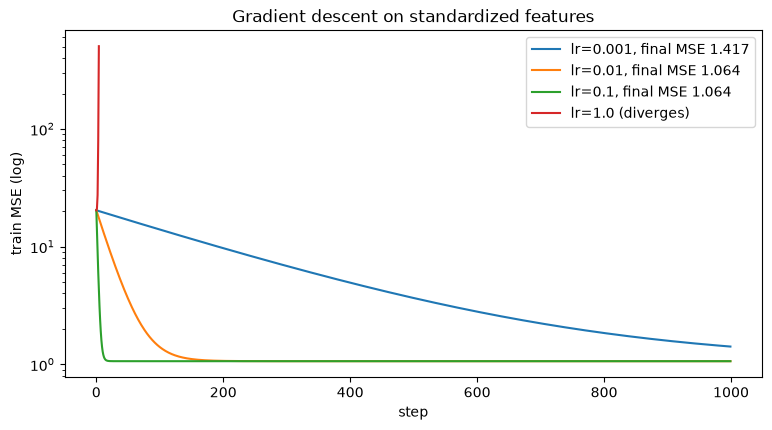

lr=0.001  MSE step 0 20.366  step 10 19.6  step 100 14  step 999 1.42
lr=0.01   MSE step 0 20.366  step 10 13.9  step 100 1.4  step 999 1.06
lr=0.1    MSE step 0 20.366  step 10 1.29  step 100 1.06  step 999 1.06
lr=1.0    MSE step 0 20.366  step 10 1.48e+08  step 100 2.74e+90  step 999 nan


In [4]:
runs = {lr: LinearRegressionGD(lr=lr, n_steps=1000).fit(Z_train, y_train) for lr in [0.001, 0.01, 0.1, 1.0]}

fig, ax = plt.subplots(figsize=(9, 4.5))
for lr, m in runs.items():
    losses = np.array(m.losses_)
    ok = np.isfinite(losses) & (losses < 1e3)
    label = f"lr={lr}" + (" (diverges)" if not ok.all() or losses[-1] > losses[0] else f", final MSE {losses[-1]:.3f}")
    ax.plot(np.flatnonzero(ok), losses[ok], label=label)
ax.set(yscale="log", xlabel="step", ylabel="train MSE (log)", title="Gradient descent on standardized features")
ax.legend()
plt.savefig(FIG / "rating_gd_lr.png", dpi=120, bbox_inches="tight")
plt.show()

for lr, m in runs.items():
    loss = m.losses_
    print(f"lr={lr:<6} MSE step 0 {loss[0]:.3f}  step 10 {loss[10]:.3g}  step 100 {loss[100]:.3g}  step 999 {loss[-1]:.3g}")

## Compare with scikit-learn on validation

In [5]:
gd = runs[0.1]
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "GradientBoostingRegressor": GradientBoostingRegressor(n_estimators=200, max_depth=3, subsample=0.5, random_state=42),
}
preds = {"Global mean": np.full(len(y_val), global_rating), "GD from scratch (lr=0.1)": gd.predict(Z_val)}
for name, m in models.items():
    t = time.time()
    preds[name] = m.fit(Z_train, y_train).predict(Z_val)
    print(f"{name}: {time.time() - t:.0f}s")

rows = {}
for name, p in preds.items():
    p = np.clip(p, 1, 5)
    rows[name] = {"RMSE": root_mean_squared_error(y_val, p), "MAE": mean_absolute_error(y_val, p),
                  "RMSE warm users": root_mean_squared_error(y_val[warm], p[warm]),
                  "RMSE cold users": root_mean_squared_error(y_val[~warm], p[~warm])}
results = pd.DataFrame(rows).T.round(4)
results

LinearRegression: 0s
Ridge: 0s


GradientBoostingRegressor: 8s


,RMSE,MAE,RMSE warm users,RMSE cold users
Global mean,1.0907,0.8390,1.1844,0.9169
GD from scratch (lr=0.1),1.0696,0.7877,1.1537,0.9155
LinearRegression,1.0696,0.7877,1.1537,0.9155
Ridge,1.0696,0.7877,1.1537,0.9155
GradientBoostingRegressor,1.0671,0.7904,1.1442,0.9270


In [6]:
ols = models["LinearRegression"]
print(pd.DataFrame({"GD weight": gd.coef_, "sklearn weight": ols.coef_}, index=FEATURES).round(4))
print(f"intercept GD {gd.intercept_:.4f}  sklearn {ols.intercept_:.4f}")
gap = abs(results.loc["GD from scratch (lr=0.1)", "RMSE"] - results.loc["LinearRegression", "RMSE"])
print(f"RMSE gap GD vs sklearn LinearRegression: {gap:.5f}")
assert gap < 1e-3

                 GD weight  sklearn weight
user_avg_rating     0.4548          0.4548
item_avg_rating     0.1794          0.1794
price               0.0097          0.0097
avg_sentiment       0.0356          0.0356
intercept GD 4.3619  sklearn 4.3619
RMSE gap GD vs sklearn LinearRegression: 0.00000


## Save the from-scratch model for the dashboard's "expected rating"

In [7]:
MODELS.mkdir(exist_ok=True)
joblib.dump({"features": FEATURES, "scaler": scaler, "coef": gd.coef_, "intercept": gd.intercept_,
             "global_rating": global_rating, "clip": (1, 5)}, MODELS / "rating_gd.joblib")
print("saved", MODELS / "rating_gd.joblib")

saved /Users/karan18/ShopRank/ShopRank/models/rating_gd.joblib
